In [1]:
import matplotlib.pyplot as plt
%load_ext autoreload
%autoreload 2

In [2]:
from models.mm_mode_transposed_model import MarkovModeTransposedModel
from priors.alpha_prior import get_d2g_alpha
from priors.transition_prior import TransitionPrior
import pymc as pm

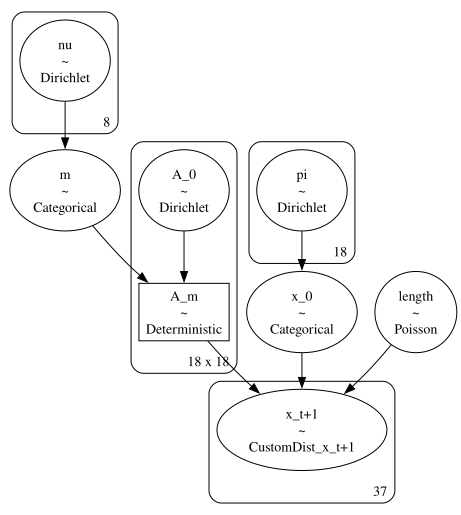

In [3]:
model = MarkovModeTransposedModel()
model.alpha = get_d2g_alpha(model.V)

beta = TransitionPrior(model.V)

beta.prefer_small_intervals(5,1)
beta.prefer_low_register(1,2,2)
beta.penalize_repeated_notes(0.3)
model.beta = beta.get_beta()
model.build_model()
pm.model_to_graphviz(model.model)


In [4]:
#samples = model.prior_predict(1)
#model.show_melody(samples[0])

In [5]:
#samples

In [6]:
#import models.model_utils as u

#u.plot_heatmap(samples[0]["A_0"].sel(chain=0,draw=0).to_numpy())


In [7]:

#u.plot_heatmap(samples[0]["A_m"].sel(chain=0,draw=0).to_numpy())

In [8]:
import data.GradualePipeline as GP
data = GP.GradualePipeline.load("data/processed/dataset_pitches_modes.pkl")
data

{'x_0_obs': array([ 6,  7,  7,  2,  6,  3,  7,  5,  6,  3,  5,  5,  5,  3,  5,  3,  3,
         4,  6,  3,  3,  6,  5,  6,  7,  5,  4,  2,  6,  5,  5,  3,  3,  6,
         9,  5,  5,  7,  6,  7,  3,  3,  6,  6,  5,  9,  3,  7,  9,  3,  3,
         5,  3,  6,  8,  6,  8,  6, 10,  6,  5,  3,  9,  6,  9,  8,  6,  5,
         3,  4,  3,  9,  9,  3,  7,  2,  9,  3,  3,  2,  6,  2,  3,  2,  3,
         6,  3,  3,  3,  7,  6,  5,  6,  5,  3,  7,  5,  7,  6,  6,  5,  9,
         6,  3,  5,  3,  7,  5,  7,  7,  3,  4,  5,  9,  9,  3,  3,  4,  9,
         6,  3,  7,  5,  6,  3,  5,  7,  5,  7,  9,  3,  6,  3,  3]),
 'x_t_obs': array([[ 6,  7,  6, ...,  6,  5,  5],
        [ 7,  7,  5, ...,  5,  5,  3],
        [ 8,  6,  6, ...,  5,  6,  3],
        ...,
        [-1, -1, -1, ..., -1, -1, -1],
        [-1, -1, -1, ..., -1, -1, -1],
        [-1, -1, -1, ..., -1, -1, -1]], shape=(428, 134)),
 'lengths_obs': array([385, 201, 104,  80, 222, 211, 140, 158, 219, 279, 260,  98, 145,
        103, 109, 154

In [9]:
data["m_obs"]

array([7, 1, 3, 1, 1, 4, 5, 0, 7, 0, 4, 7, 0, 0, 5, 0, 0, 2, 3, 5, 4, 2,
       1, 1, 0, 5, 1, 7, 6, 0, 5, 0, 4, 6, 4, 1, 4, 0, 7, 1, 2, 0, 5, 3,
       3, 6, 0, 0, 1, 5, 0, 7, 0, 7, 5, 7, 0, 6, 6, 2, 5, 0, 7, 7, 7, 2,
       6, 4, 3, 2, 7, 6, 4, 4, 7, 1, 1, 4, 1, 7, 1, 2, 2, 0, 3, 2, 3, 3,
       7, 4, 6, 4, 6, 2, 0, 1, 4, 4, 6, 7, 3, 1, 1, 1, 3, 5, 1, 4, 1, 1,
       3, 3, 7, 1, 6, 5, 0, 3, 4, 2, 0, 4, 4, 7, 7, 3, 5, 7, 5, 4, 1, 7,
       4, 0])

In [ ]:
trace = model.fit(
        data,
        draws=3000,
        tune=2000,
        description="init",
        use_latest=True
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [nu, A_0, pi]


Output()

In [ ]:
pm.model_to_graphviz(model.model)

In [ ]:
import arviz as az
az.plot_trace(trace, var_names=["nu", "A_0", "pi"])

In [ ]:
az.plot_energy(trace);

In [ ]:
from analysis.visualise_posterior import plot_mean_heatmap, plot_transition_densities

In [ ]:
plot_mean_heatmap(model.trace)

In [ ]:
plot_transition_densities(model.trace, matrix_name="A_0")